# Force traces — EFC_compositional

Three views of the smoothed force traces, each cell self-contained so you can set the
trial you want at the top and re-run just that cell.

1. **any single trial** — all five fingers with `RT`, `ET` and `MD` marked
2. **pre vs post training** — the same 4-finger chord before and after the components were trained
3. **the trained components across days** — day 1 / 2 / 3 overlaid

Set any `TN` (or `BN`) to `None` and a trial is picked at random.
Needs `analysis/s<sn>.csv` and `analysis/s<sn>_mov.pkl` from `preprocess.ipynb`.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## =================
SN = 101
SEED = None
## =================

ANALYSIS_DIR = ROOT / "analysis"
WAIT_PLAN, WAIT_EXEC = 2, 3       # state codes, see EFC_compositional.h

TRAINED_CHORDS = [12999, 99912]   # the 2-finger components
TESTED_CHORDS = [12912, 12921, 21912, 21921]
from utils.design import TEST1_BLOCKS, TEST2_BLOCKS   # day 1 before / day 3 after training

FINGERS = ["thumb", "index", "middle", "ring", "pinky"]
STATE_OF = {"1": "ext", "2": "flex", "9": "rel"}

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
PAL = dict(zip(FINGERS, sns.color_palette("colorblind", 5)))

df = pd.read_csv(ANALYSIS_DIR / f"s{SN}.csv")
mov = pd.read_pickle(ANALYSIS_DIR / f"s{SN}_mov.pkl")
REC = {(r.BN, r.TN): r for r in mov.itertuples()}
rng = np.random.default_rng(SEED)

print(f"s{SN}: {len(df)} trials, blocks {df.BN.min()}-{df.BN.max()}, "
      f"days {sorted(df.day.unique().tolist())}")
print(f"chords present: {sorted(df.chordID.unique().tolist())}")


s101: 840 trials, blocks 1-42, days [1, 2, 3]
chords present: [12912, 12921, 12999, 21912, 21921, 99912]


## 1. Any single trial

Set `BN` / `TN` to pin a trial, or leave either as `None` to pick at random.

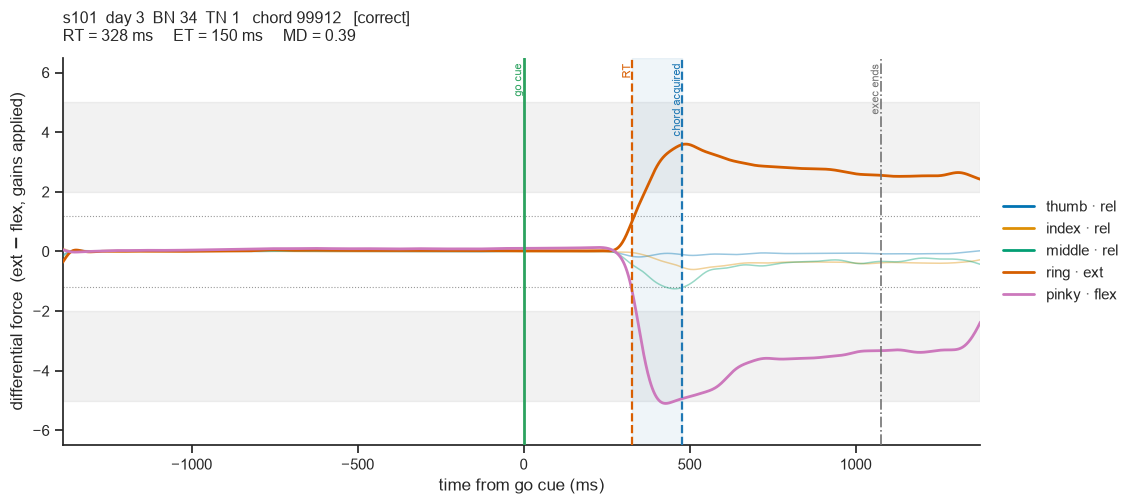

In [2]:
BN = None            # block number, None -> random
TN = None            # trial number, None -> random
ONLY_CORRECT = True  # when picking at random, only consider correct trials

# ---- pick the trial
pool = df[df.trialPoint == 1] if ONLY_CORRECT else df
if BN is not None:
    pool = pool[pool.BN == BN]
if TN is not None:
    pool = pool[pool.TN == TN]
if pool.empty:
    raise ValueError(f"no trial matches BN={BN}, TN={TN} (ONLY_CORRECT={ONLY_CORRECT})")
tr = pool.iloc[rng.integers(len(pool))]

# ---- pull the trace, align on the go cue
rec = REC[(int(tr.BN), int(tr.TN))]
t0 = rec.t[rec.state == WAIT_EXEC][0]
tt = rec.t - t0
plan = np.where(rec.state == WAIT_PLAN)[0]
ex = np.where(rec.state == WAIT_EXEC)[0]
lo = tt[plan[0]] if len(plan) else tt[0]
hi = tt[ex[-1]] + 300
m = (tt >= lo) & (tt <= hi)

chord = str(int(tr.chordID))
labels = [f"{FINGERS[i]} · {STATE_OF[chord[i]]}" for i in range(5)]
tidy = pd.DataFrame({"time": np.tile(tt[m], 5),
                     "force": rec.force[m].T.ravel(),
                     "finger": np.repeat(labels, m.sum())})

fig, ax = plt.subplots(figsize=(11.5, 5.2))

# target zones and baseline
ax.axhspan(tr.extBotThresh, tr.extTopThresh, color="0.5", alpha=.10, zorder=0)
ax.axhspan(tr.flexTopThresh, tr.flexBotThresh, color="0.5", alpha=.10, zorder=0)
for y in (tr.baselineTopThresh, -tr.baselineTopThresh):
    ax.axhline(y, color="0.6", lw=.8, ls=":", zorder=1)

n_before = len(ax.lines)        # the threshold axhlines are already in ax.lines
sns.lineplot(data=tidy, x="time", y="force", hue="finger", hue_order=labels,
             palette={lab: PAL[FINGERS[i]] for i, lab in enumerate(labels)},
             lw=2, errorbar=None, ax=ax, zorder=3)
for line, d in zip(ax.lines[n_before:], chord):   # fade fingers that should stay relaxed
    if d == "9":
        line.set_alpha(.40); line.set_linewidth(1.1)

# events
ax.axvline(0, color="#2ca25f", lw=2, zorder=4)
ax.axvline(tr.RT, color="#d95f02", lw=1.6, ls="--", zorder=4)
if tr.trialPoint == 1:
    ax.axvline(tr.RT + tr.ET, color="#1f78b4", lw=1.6, ls="--", zorder=4)
    ax.axvspan(tr.RT, tr.RT + tr.ET, color="#1f78b4", alpha=.07, zorder=1)
ax.axvline(tt[ex[-1]], color="0.45", lw=1.2, ls="-.", zorder=4)
for x, txt, col in [(0, "go cue", "#2ca25f"), (tr.RT, "RT", "#d95f02"),
                    (tr.RT + tr.ET if tr.trialPoint == 1 else np.nan, "chord acquired", "#1f78b4"),
                    (tt[ex[-1]], "exec ends", "0.45")]:
    if np.isfinite(x):
        ax.text(x, 6.3, txt, rotation=90, fontsize=8, color=col, ha="right", va="top")

outcome = "correct" if tr.trialPoint == 1 else ("PLAN ERROR" if tr.planError == 1 else "failed")
md_txt = f"MD = {tr.MD:.2f}" if np.isfinite(tr.MD) else "MD = n/a (incorrect trial)"
ax.set_title(f"s{SN}  day {int(tr.day)}  BN {int(tr.BN)}  TN {int(tr.TN)}   "
             f"chord {chord}   [{outcome}]\n"
             f"RT = {tr.RT:.0f} ms     ET = {tr.ET:.0f} ms     {md_txt}",
             fontsize=11.5, loc="left", pad=12)
ax.set_xlabel("time from go cue (ms)")
ax.set_ylabel("differential force  (ext $-$ flex, gains applied)")
ax.set_xlim(lo, hi); ax.set_ylim(-6.5, 6.5)
ax.legend(title=None, frameon=False, loc="center left", bbox_to_anchor=(1.01, .5))
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## 2. Pre vs post training — one 4-finger chord

The same chord before any component training (Test 1, day 1) and after it
(Test 2, day 3), as **stacked panels sharing both axes** so the change in duration and
in finger timing is read off vertically.

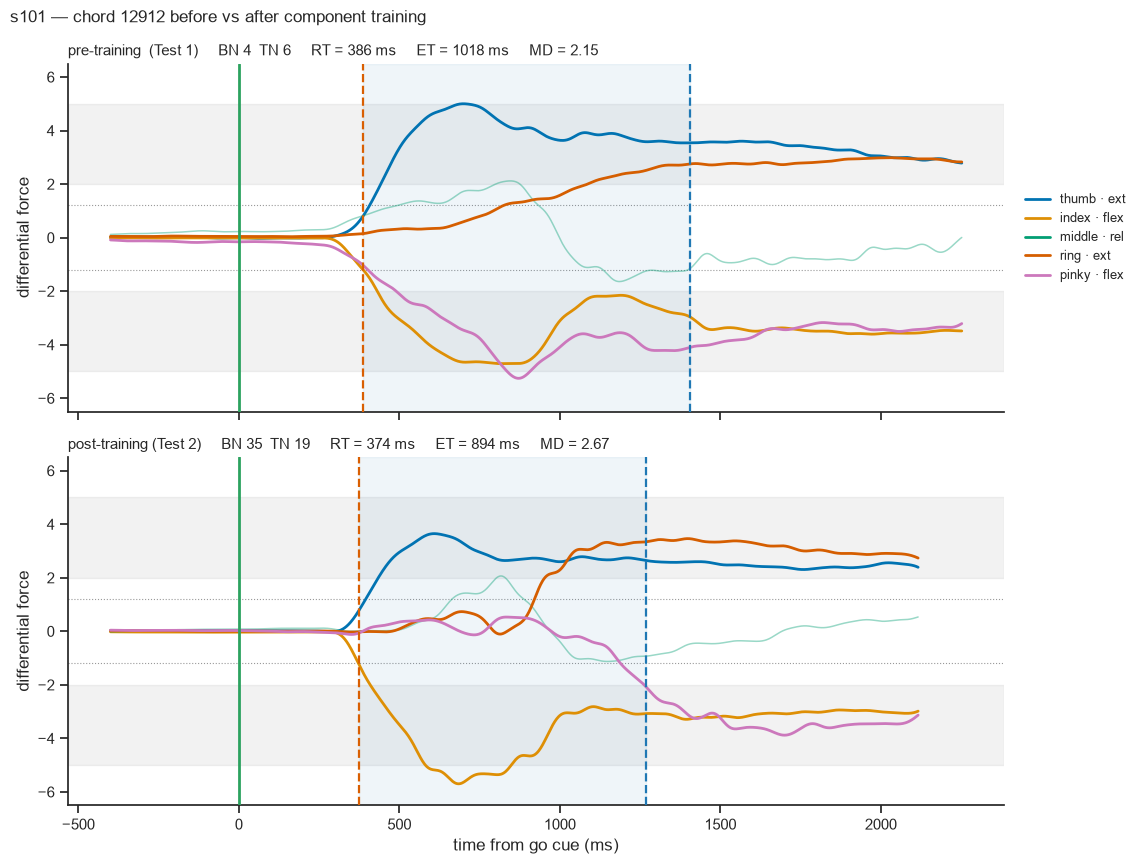

In [3]:
CHORD = 12912        # <<< which 4-finger chord
PRE = (None, None)   # <<< (BN, TN) from Test 1, None -> random
POST = (None, None)  # <<< (BN, TN) from Test 2, None -> random
ONLY_CORRECT = True

picks = {}
for phase, (blocks, (bn, tn)) in {"pre-training  (Test 1)": (TEST1_BLOCKS, PRE),
                                  "post-training (Test 2)": (TEST2_BLOCKS, POST)}.items():
    pool = df[(df.chordID == CHORD) & (df.BN.isin(blocks))]
    if ONLY_CORRECT:
        pool = pool[pool.trialPoint == 1]
    if bn is not None: pool = pool[pool.BN == bn]
    if tn is not None: pool = pool[pool.TN == tn]
    if pool.empty:
        print(f"NOTE: no trial for '{phase}' - panel skipped")
    else:
        picks[phase] = pool.iloc[rng.integers(len(pool))]

chord = str(CHORD)
labels = [f"{FINGERS[i]} · {STATE_OF[chord[i]]}" for i in range(5)]
pal = {lab: PAL[FINGERS[i]] for i, lab in enumerate(labels)}

fig, axes = plt.subplots(len(picks), 1, figsize=(11.5, 4.4 * len(picks)),
                         sharex=True, sharey=True)
for ax, (phase, tr) in zip(np.atleast_1d(axes), picks.items()):
    rec = REC[(int(tr.BN), int(tr.TN))]
    t0 = rec.t[rec.state == WAIT_EXEC][0]
    tt = rec.t - t0
    ex = np.where(rec.state == WAIT_EXEC)[0]
    m = (tt >= -400) & (tt <= tt[ex[-1]] + 250)

    ax.axhspan(tr.extBotThresh, tr.extTopThresh, color="0.5", alpha=.10, zorder=0)
    ax.axhspan(tr.flexTopThresh, tr.flexBotThresh, color="0.5", alpha=.10, zorder=0)
    for y in (tr.baselineTopThresh, -tr.baselineTopThresh):
        ax.axhline(y, color="0.6", lw=.8, ls=":", zorder=1)

    tidy = pd.DataFrame({"time": np.tile(tt[m], 5),
                         "force": rec.force[m].T.ravel(),
                         "finger": np.repeat(labels, m.sum())})
    n_before = len(ax.lines)
    sns.lineplot(data=tidy, x="time", y="force", hue="finger", hue_order=labels,
                 palette=pal, lw=2, errorbar=None, ax=ax, legend=False, zorder=3)
    for line, d in zip(ax.lines[n_before:], chord):
        if d == "9":
            line.set_alpha(.40); line.set_linewidth(1.1)

    ax.axvline(0, color="#2ca25f", lw=2, zorder=4)
    ax.axvline(tr.RT, color="#d95f02", lw=1.6, ls="--", zorder=4)
    if tr.trialPoint == 1:
        ax.axvline(tr.RT + tr.ET, color="#1f78b4", lw=1.6, ls="--", zorder=4)
        ax.axvspan(tr.RT, tr.RT + tr.ET, color="#1f78b4", alpha=.07, zorder=1)
    md_txt = f"MD = {tr.MD:.2f}" if np.isfinite(tr.MD) else "MD = n/a"
    ax.set_title(f"{phase}     BN {int(tr.BN)}  TN {int(tr.TN)}     "
                 f"RT = {tr.RT:.0f} ms     ET = {tr.ET:.0f} ms     {md_txt}",
                 fontsize=10.5, loc="left")
    ax.set_ylabel("differential force")
    ax.set_ylim(-6.5, 6.5)

np.atleast_1d(axes)[-1].set_xlabel("time from go cue (ms)")
handles = [Line2D([], [], color=pal[lab], lw=2, label=lab) for lab in labels]
np.atleast_1d(axes)[0].legend(handles=handles, title=None, frameon=False,
                              loc="center left", bbox_to_anchor=(1.01, .5), fontsize=9)
fig.suptitle(f"s{SN} — chord {CHORD} before vs after component training",
             fontsize=12.5, x=.01, ha="left")
sns.despine(fig=fig)
plt.tight_layout()
plt.show()

## 3. The trained components across days

One trial of each component per training day, as **stacked panels — one row per day,
one column per component** — so the change over training reads top to bottom.

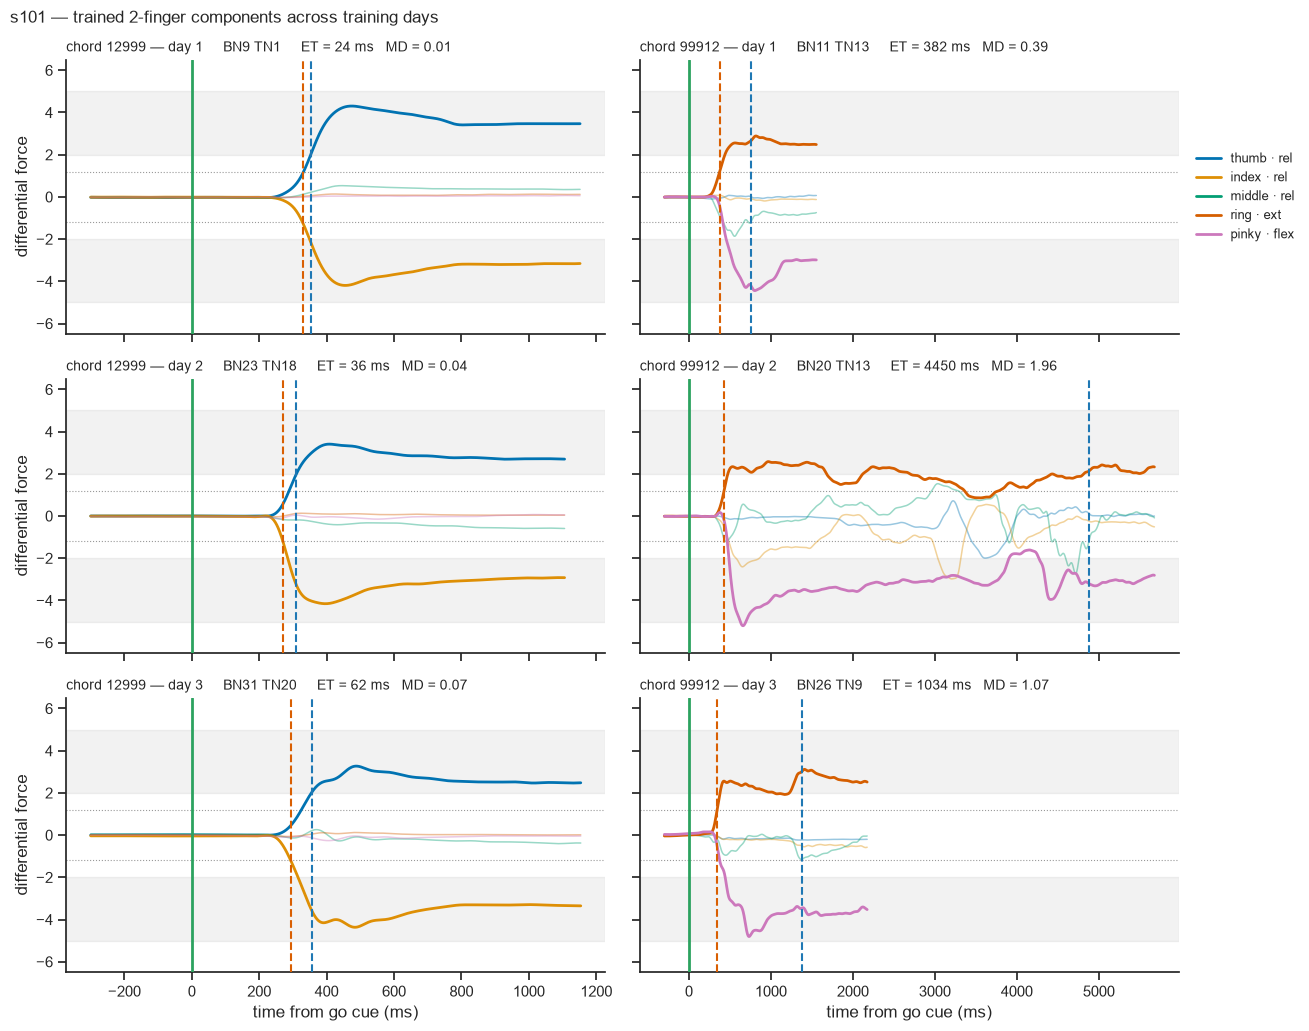

In [4]:
# <<< {day: {chordID: (BN, TN)}} - set any entry to pin it, None picks at random
PICK = {1: {12999: None, 99912: None},
        2: {12999: None, 99912: None},
        3: {12999: None, 99912: None}}
ONLY_CORRECT = True

days = sorted(PICK)
fig, axes = plt.subplots(len(days), len(TRAINED_CHORDS),
                         figsize=(6.6 * len(TRAINED_CHORDS), 3.5 * len(days)),
                         sharex="col", sharey=True, squeeze=False)

for col, chord_id in enumerate(TRAINED_CHORDS):
    chord = str(chord_id)
    labels = [f"{FINGERS[i]} · {STATE_OF[chord[i]]}" for i in range(5)]
    pal = {lab: PAL[FINGERS[i]] for i, lab in enumerate(labels)}

    for row, day in enumerate(days):
        ax = axes[row][col]
        pool = df[(df.chordID == chord_id) & (df.day == day)]
        if ONLY_CORRECT:
            pool = pool[pool.trialPoint == 1]
        sel = PICK[day].get(chord_id)
        if sel is not None:
            bn, tn = sel
            if bn is not None: pool = pool[pool.BN == bn]
            if tn is not None: pool = pool[pool.TN == tn]
        if pool.empty:
            ax.text(.5, .5, f"no data — day {day}", transform=ax.transAxes,
                    ha="center", va="center", color="0.6")
            continue

        tr = pool.iloc[rng.integers(len(pool))]
        rec = REC[(int(tr.BN), int(tr.TN))]
        t0 = rec.t[rec.state == WAIT_EXEC][0]
        tt = rec.t - t0
        ex = np.where(rec.state == WAIT_EXEC)[0]
        m = (tt >= -300) & (tt <= tt[ex[-1]] + 200)

        ax.axhspan(2, 5, color="0.5", alpha=.10, zorder=0)
        ax.axhspan(-5, -2, color="0.5", alpha=.10, zorder=0)
        for y in (1.2, -1.2):
            ax.axhline(y, color="0.6", lw=.8, ls=":", zorder=1)

        tidy = pd.DataFrame({"time": np.tile(tt[m], 5),
                             "force": rec.force[m].T.ravel(),
                             "finger": np.repeat(labels, m.sum())})
        n_before = len(ax.lines)
        sns.lineplot(data=tidy, x="time", y="force", hue="finger", hue_order=labels,
                     palette=pal, lw=2, errorbar=None, ax=ax, legend=False, zorder=3)
        for line, d in zip(ax.lines[n_before:], chord):
            if d == "9":
                line.set_alpha(.40); line.set_linewidth(1.1)

        ax.axvline(0, color="#2ca25f", lw=2, zorder=4)
        ax.axvline(tr.RT, color="#d95f02", lw=1.5, ls="--", zorder=4)
        if tr.trialPoint == 1:
            ax.axvline(tr.RT + tr.ET, color="#1f78b4", lw=1.5, ls="--", zorder=4)
        ax.set_title(f"chord {chord_id} — day {day}     BN{int(tr.BN)} TN{int(tr.TN)}     "
                     f"ET = {tr.ET:.0f} ms   MD = {tr.MD:.2f}", fontsize=10, loc="left")
        ax.set_ylim(-6.5, 6.5)
        if col == 0:
            ax.set_ylabel("differential force")
        if row == len(days) - 1:
            ax.set_xlabel("time from go cue (ms)")

        if row == 0 and col == len(TRAINED_CHORDS) - 1:
            handles = [Line2D([], [], color=pal[lab], lw=2, label=lab) for lab in labels]
            ax.legend(handles=handles, title=None, frameon=False,
                      loc="center left", bbox_to_anchor=(1.01, .5), fontsize=9)

fig.suptitle(f"s{SN} — trained 2-finger components across training days",
             fontsize=12.5, x=.01, ha="left")
sns.despine(fig=fig)
plt.tight_layout()
plt.show()